# Learning RNA velocity and generative modelling on pancreas endocrinogenesis

In [81]:
import scanpy as sc
import scvelo as scv
import cellrank as cr
import numpy as np
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import recall_score
import copy

device = 'cuda' if torch.cuda.is_available() else 'cpu'

### Data

In [2]:
adata = scv.datasets.pancreas()
print(adata)

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'


In [3]:
print(adata.obs.columns)
print(adata.obs['clusters'].value_counts())
print(adata.layers.keys())

Index(['clusters_coarse', 'clusters', 'S_score', 'G2M_score'], dtype='object')
clusters
Ductal           916
Ngn3 high EP     642
Pre-endocrine    592
Beta             591
Alpha            481
Ngn3 low EP      262
Epsilon          142
Delta             70
Name: count, dtype: int64
KeysView(Layers with keys: spliced, unspliced)


In [4]:
print(adata.obs['clusters'].value_counts())

clusters
Ductal           916
Ngn3 high EP     642
Pre-endocrine    592
Beta             591
Alpha            481
Ngn3 low EP      262
Epsilon          142
Delta             70
Name: count, dtype: int64


In [5]:
print(type(adata.X), adata.X.max())

<class 'scipy.sparse._csr.csr_matrix'> 2286.0


In [6]:
print(adata.X[:5, :10].toarray())

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


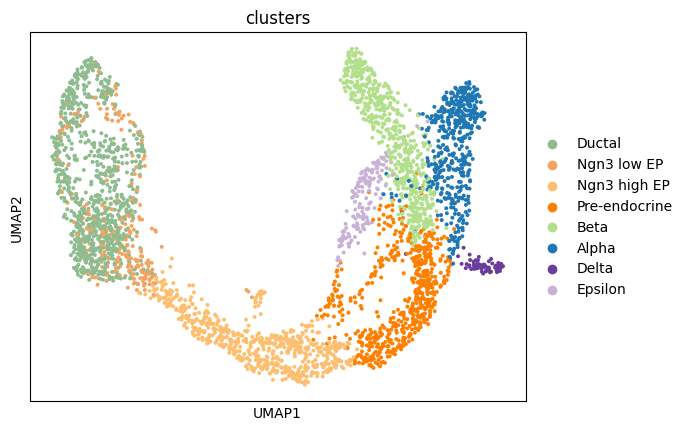

In [7]:
sc.pl.umap(adata, color='clusters')

### Preprocessing and clustering

In [8]:
print(np.allclose(adata.X.data, np.round(adata.X.data)))

True


In [9]:
totals = np.asarray(adata.X.sum(axis=1)).ravel()
print(totals.min(), np.median(totals), totals.max())

3020.0 6194.0 18524.0


In [10]:
adata.layers['counts'] = adata.X.copy()                
sc.pp.normalize_total(adata, target_sum=1e4)           
sc.pp.log1p(adata)                                     
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
print(adata.var['highly_variable'].sum())              

2000


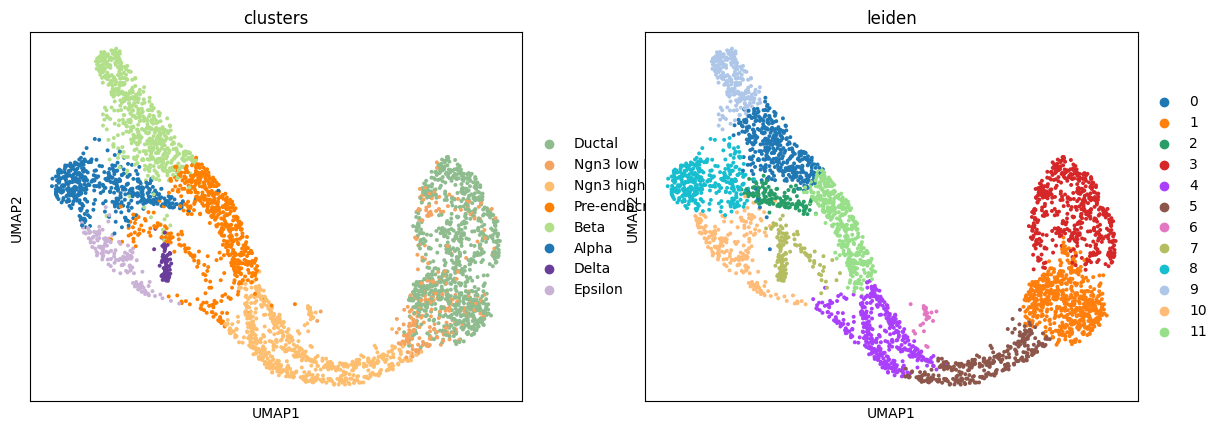

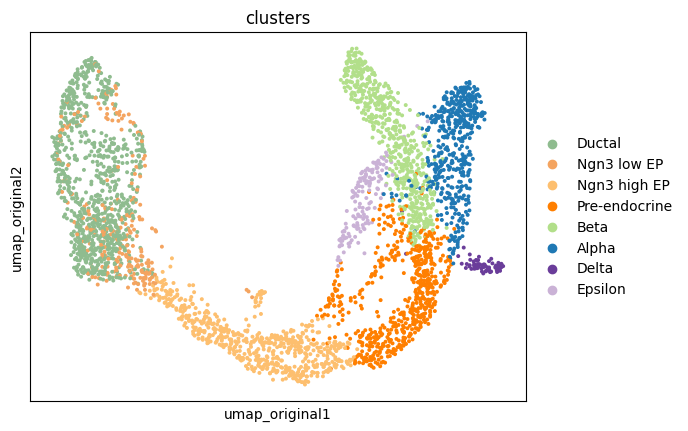

In [11]:
adata.obsm['X_umap_original'] = adata.obsm['X_umap'].copy()

sc.tl.pca(adata, n_comps=30)                      
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)  
sc.tl.umap(adata)                                 
sc.tl.leiden(adata, resolution=0.8, flavor='igraph',
             n_iterations=2, directed=False, key_added='leiden')

sc.pl.umap(adata, color=['clusters', 'leiden'])
sc.pl.embedding(adata, basis='umap_original', color='clusters')

In [12]:
print(adjusted_rand_score(adata.obs['clusters'], adata.obs['leiden']))
print(adata.obs['leiden'].nunique())

0.5202889195713197
12


In [13]:
ct = pd.crosstab(adata.obs['clusters'], adata.obs['leiden'])
print(ct)
print(pd.crosstab(adata.obs['clusters'], adata.obs['leiden'], normalize='index').round(2))

leiden           0    1    2    3    4    5   6   7    8    9   10   11
clusters                                                               
Ductal           0  479    0  425    0   12   0   0    0    0    0    0
Ngn3 low EP      0  121    0   79    0   60   2   0    0    0    0    0
Ngn3 high EP     0    0    0    0  372  237  23   0    0    0    0   10
Pre-endocrine   61    0   30    0   42    0   1  58    1    0   34  365
Beta           322    0    3    0    0    0   0   8   16  238    2    2
Alpha            9    0  103    0    0    0   0   0  336    0   32    1
Delta            1    0    0    0    0    0   0  69    0    0    0    0
Epsilon          0    0    0    0    0    0   0   0    2    0  140    0
leiden            0     1     2     3     4     5     6     7     8    9   
clusters                                                                   
Ductal         0.00  0.52  0.00  0.46  0.00  0.01  0.00  0.00  0.00  0.0  \
Ngn3 low EP    0.00  0.46  0.00  0.30  0.00  0.23  0

In [14]:
for r in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    key = f'leiden_{r}'
    sc.tl.leiden(adata, resolution=r, flavor='igraph',
                 n_iterations=2, directed=False, key_added=key)
    print(r, adata.obs[key].nunique(),
          round(adjusted_rand_score(adata.obs['clusters'], adata.obs[key]), 3))

0.2 5 0.563
0.3 7 0.551
0.4 9 0.52
0.5 9 0.616
0.6 9 0.619
0.8 12 0.52


In [15]:
for seed in range(5):
    sc.tl.leiden(adata, resolution=0.5, flavor='igraph', n_iterations=2,
                 directed=False, key_added='tmp', random_state=seed)
    print(seed, adata.obs['tmp'].nunique(),
          round(adjusted_rand_score(adata.obs['clusters'], adata.obs['tmp']), 3))

0 9 0.616
1 9 0.613
2 9 0.618
3 10 0.439
4 10 0.51


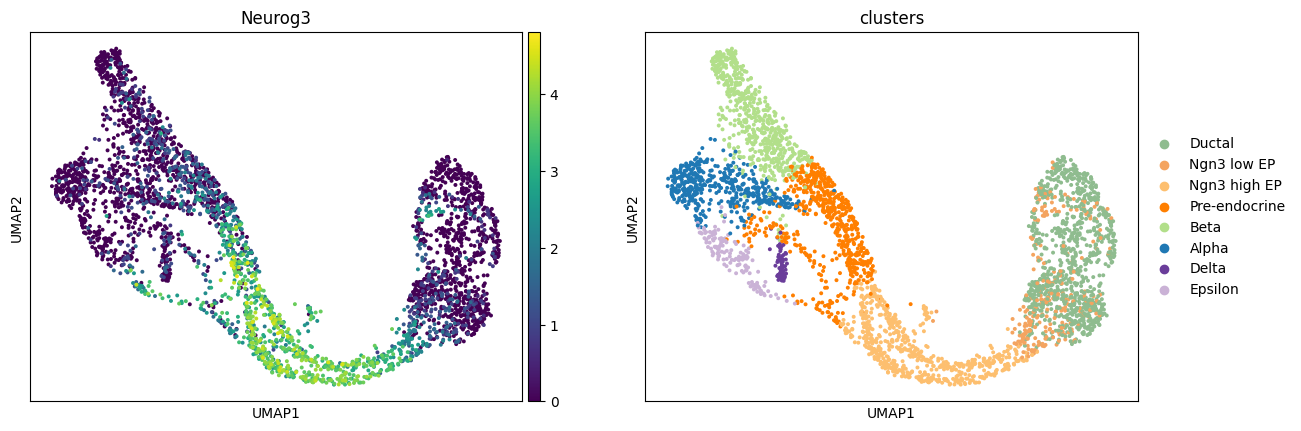

In [16]:
sc.pl.umap(adata, color=['Neurog3', 'clusters'])

In [17]:
adata.write_h5ad('pancreas_day2.h5ad')

### RNA velocity

Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
(3696, 7197)


C:\Users\USER\AppData\Local\Temp\ipykernel_5152\3127405899.py:5: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata_v, n_pcs=30, n_neighbors=30)
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\preprocessing\moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\algorithms.py:525: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities


C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\tools\optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:02) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/12 cores)


  0%|          | 0/3696 [00:00<?, ?cells/s]

    finished (0:00:28) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\algorithms.py:525: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


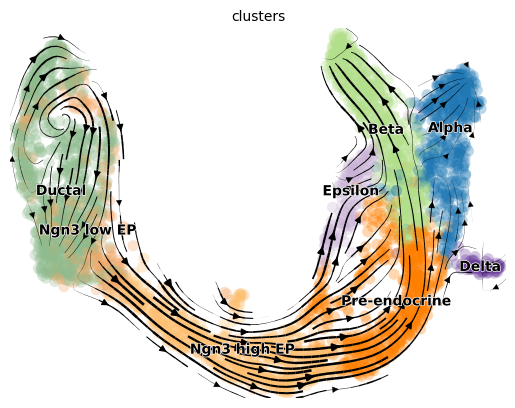

In [18]:
adata_v = scv.datasets.pancreas()
scv.pp.filter_and_normalize(adata_v, min_shared_counts=20)
print(adata_v.shape)

scv.pp.moments(adata_v, n_pcs=30, n_neighbors=30)
scv.tl.velocity(adata_v)
scv.tl.velocity_graph(adata_v)
scv.pl.velocity_embedding_stream(adata_v, basis='umap', color='clusters')

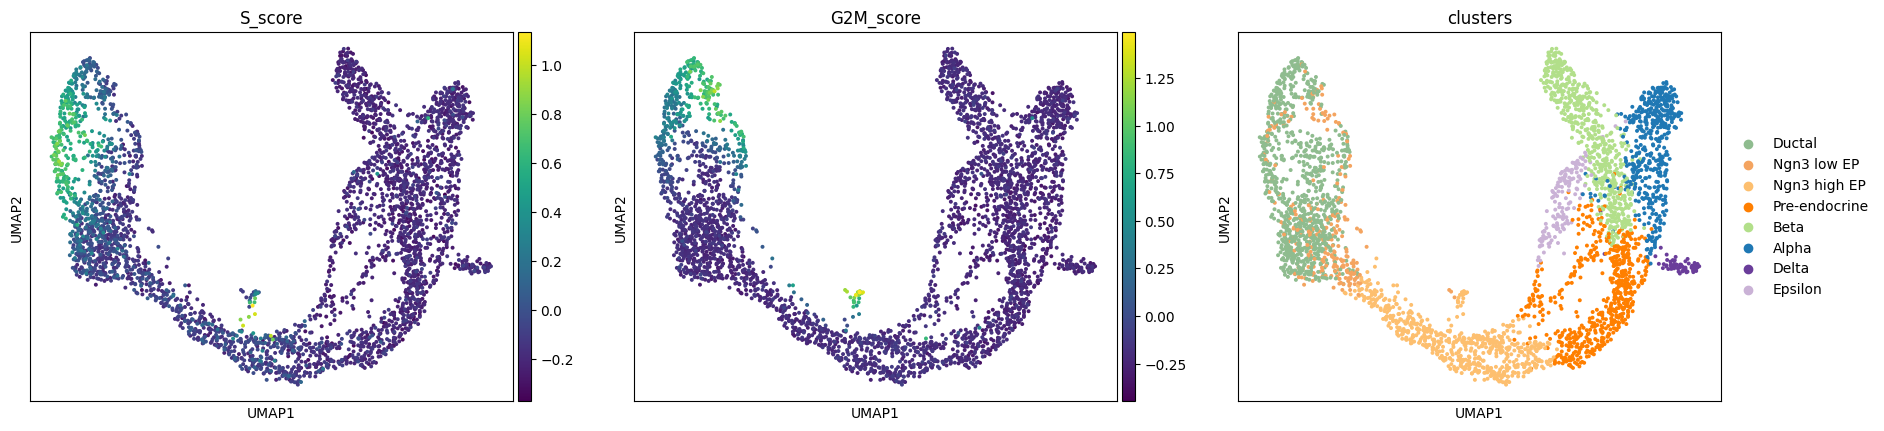

In [19]:
sc.pl.umap(adata_v, color=['S_score', 'G2M_score', 'clusters'])

In [20]:
adata_v.write_h5ad('pancreas_velocity.h5ad')

Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities


C:\Users\USER\AppData\Local\Temp\ipykernel_5152\532145332.py:3: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata_v, n_pcs=30, n_neighbors=30)
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\preprocessing\moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\algorithms.py:525: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities


C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\tools\optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:02) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/12 cores)


  0%|          | 0/3696 [00:00<?, ?cells/s]

    finished (0:00:26) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


  0%|          | 0/3696 [00:00<?, ?cell/s]

  0%|          | 0/3696 [00:00<?, ?cell/s]

C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)
C:\Users\USER\AppData\Local\Pr

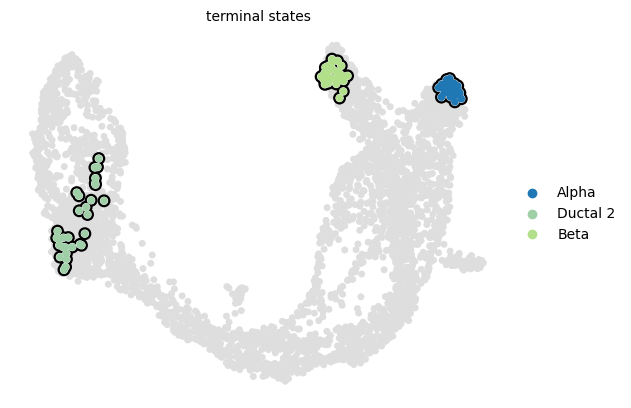

In [21]:
adata_v = scv.datasets.pancreas()
scv.pp.filter_and_normalize(adata_v, min_shared_counts=20)
scv.pp.moments(adata_v, n_pcs=30, n_neighbors=30)
scv.tl.velocity(adata_v)
scv.tl.velocity_graph(adata_v)

vk = cr.kernels.VelocityKernel(adata_v).compute_transition_matrix()
ck = cr.kernels.ConnectivityKernel(adata_v).compute_transition_matrix()
kernel = 0.8 * vk + 0.2 * ck

g = cr.estimators.GPCCA(kernel)
g.fit(cluster_key='clusters', n_states=[4, 13])
g.predict_terminal_states()
g.plot_macrostates(which='terminal', discrete=True, legend_loc='right', s=100)

Defaulting to `'gmres'` solver.


  0%|          | 0/3 [00:00<?, ?/s]

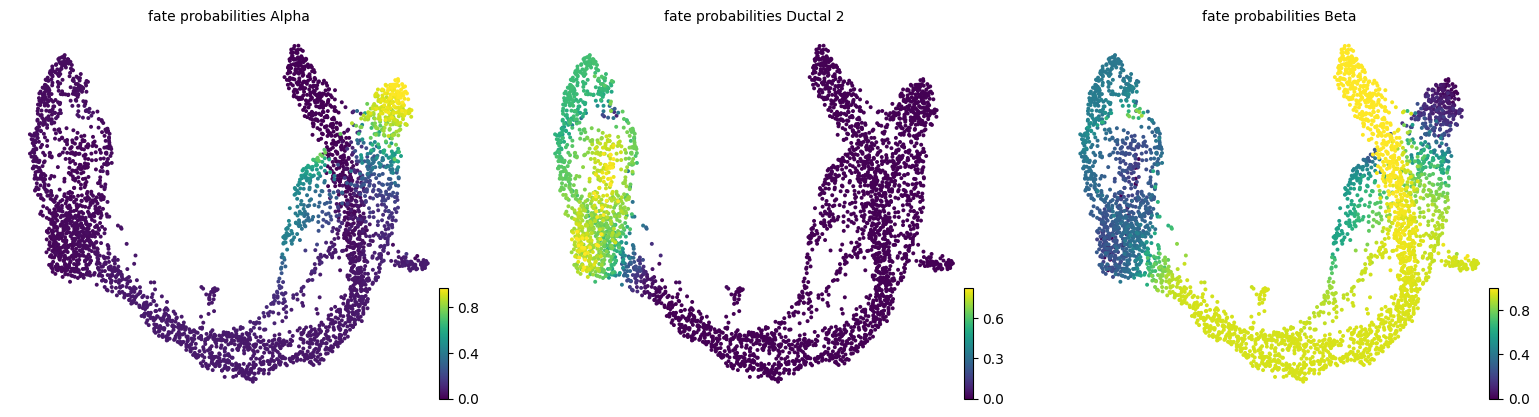

In [23]:
g.compute_fate_probabilities()
g.plot_fate_probabilities(same_plot=False)

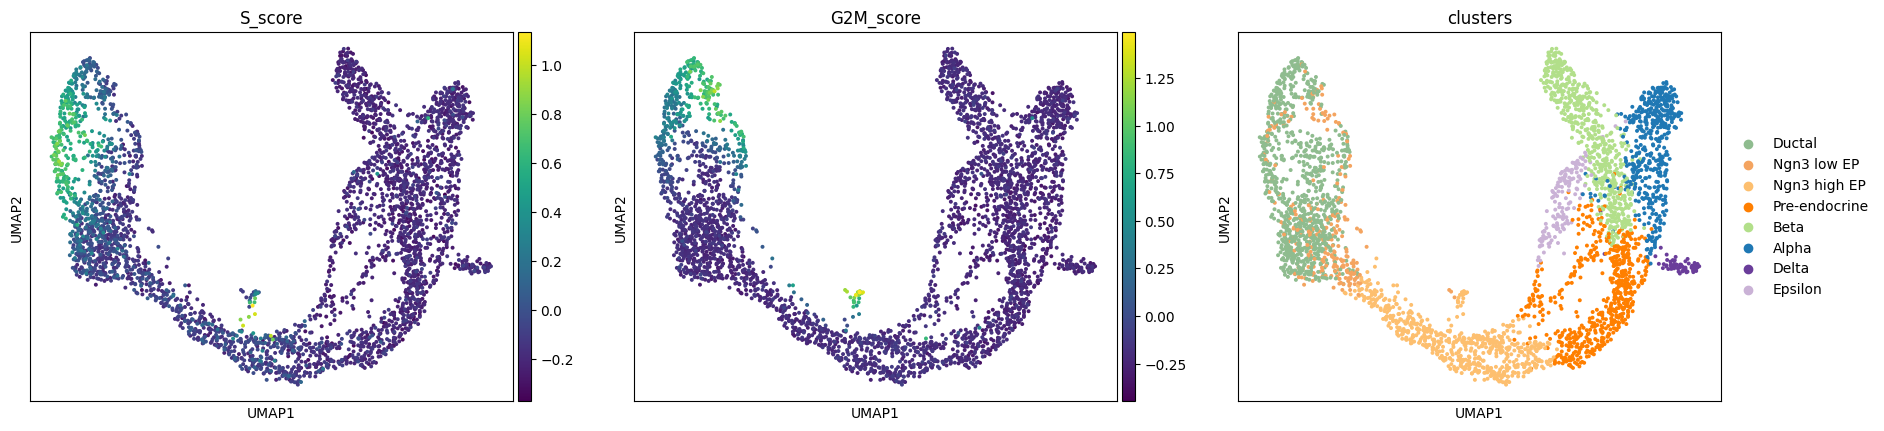

In [24]:
sc.pl.umap(adata_v, color=['S_score', 'G2M_score', 'clusters'])

In [25]:
for n in [8, 9, 10]:
    g.fit(cluster_key='clusters', n_states=n)
    g.predict_terminal_states()
    print(n, g.terminal_states.cat.categories.tolist())

8 ['Alpha', 'Ductal_3', 'Beta']
9 ['Alpha', 'Ductal_4', 'Beta']
10 ['Alpha', 'Beta']


In [26]:
g.compute_fate_probabilities()
fp = pd.DataFrame(g.fate_probabilities.X,
                  index=adata_v.obs_names,
                  columns=g.fate_probabilities.names)
print(fp.groupby(adata_v.obs['clusters']).mean().round(2))

  0%|          | 0/2 [00:00<?, ?/s]

               Alpha  Beta
clusters                  
Ductal          0.06  0.94
Ngn3 low EP     0.06  0.94
Ngn3 high EP    0.06  0.94
Pre-endocrine   0.07  0.93
Beta            0.02  0.98
Alpha           0.59  0.41
Delta           0.07  0.93
Epsilon         0.46  0.54


In [27]:
g.set_terminal_states(states=['Alpha', 'Beta', 'Delta', 'Epsilon'])
g.compute_fate_probabilities()

  0%|          | 0/4 [00:00<?, ?/s]

C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\scvelo\plotting\utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)
C:\Users\USER\AppData\Local\Pr

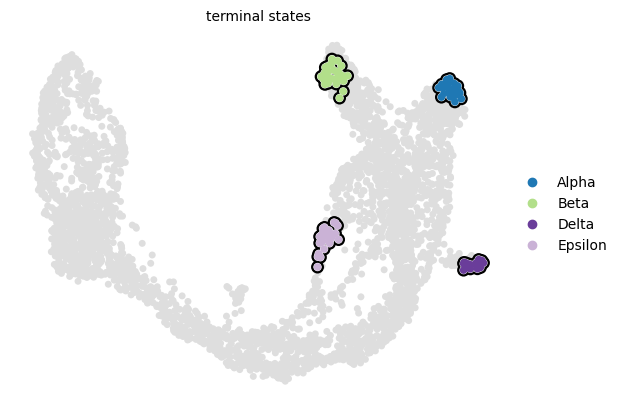

In [28]:
g.plot_macrostates(which='terminal', discrete=True, legend_loc='right', s=100)

  0%|          | 0/4 [00:00<?, ?/s]

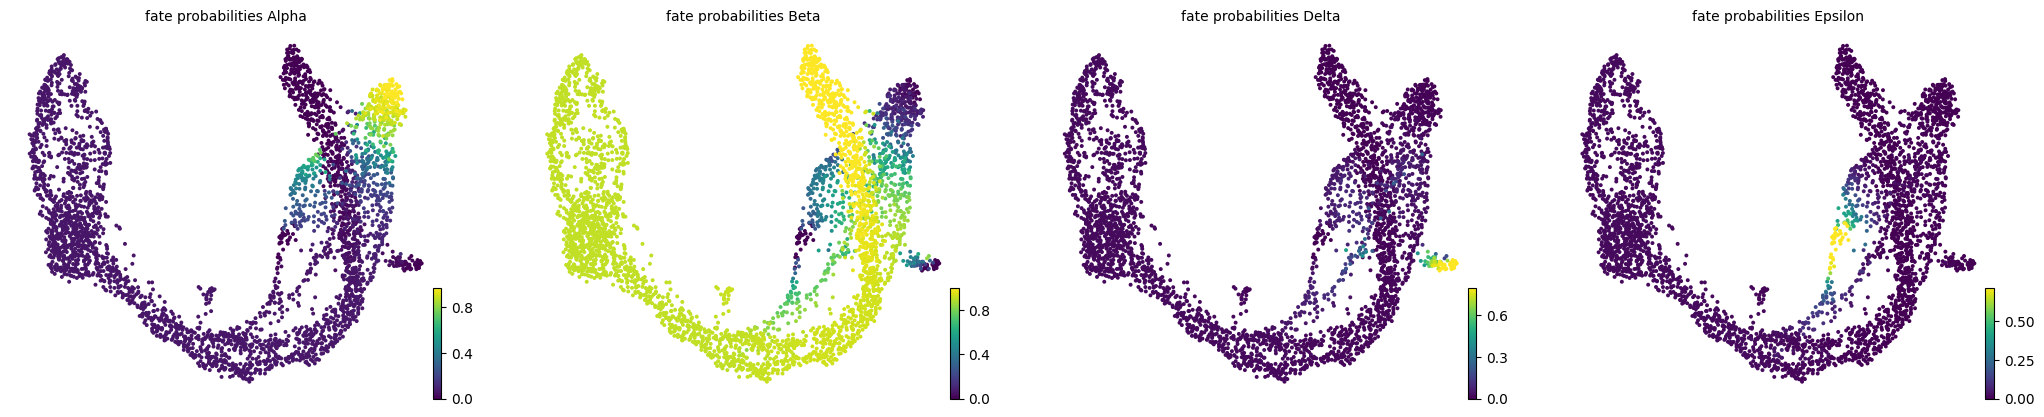

In [29]:
g.compute_fate_probabilities()
g.plot_fate_probabilities(same_plot=False)

In [30]:
adata_v.write_h5ad('pancreas_velocity.h5ad')

In [31]:
fp = pd.DataFrame(g.fate_probabilities.X,
                  index=adata_v.obs_names,
                  columns=g.fate_probabilities.names)
print(fp.groupby(adata_v.obs['clusters']).mean().round(2))

               Alpha  Beta  Delta  Epsilon
clusters                                  
Ductal          0.06  0.91   0.02     0.02
Ngn3 low EP     0.06  0.91   0.02     0.02
Ngn3 high EP    0.06  0.91   0.02     0.02
Pre-endocrine   0.06  0.88   0.03     0.03
Beta            0.02  0.97   0.00     0.00
Alpha           0.59  0.38   0.02     0.01
Delta           0.02  0.23   0.75     0.00
Epsilon         0.32  0.30   0.04     0.33


### VAE

In [32]:
adata = scv.datasets.pancreas()
print(np.allclose(adata.X.data, np.round(adata.X.data)))   # True = raw counts

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

X = adata[:, adata.var['highly_variable']].X
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
X = torch.tensor(X, dtype=torch.float32)
print(X.shape)

torch.manual_seed(0)
perm = torch.randperm(X.shape[0])
n_val = X.shape[0] // 10
val_idx, train_idx = perm[:n_val], perm[n_val:]

True
torch.Size([3696, 2000])


C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\algorithms.py:525: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])
C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\algorithms.py:525: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])


In [33]:
train_X=X[train_idx]
train_X.shape
val_X=X[val_idx]
val_X.shape

torch.Size([369, 2000])

In [34]:
class Encoder(nn.Module):
    def __init__(self, size, latent_dim):
        super(Encoder, self).__init__()
        self.fc1 = nn.Linear(size, 256)
        self.fc2 = nn.Linear(256, latent_dim)
        self.fc3 = nn.Linear(256, latent_dim)
    def forward(self, x):
        x = F.relu(self.fc1(x))
        m = self.fc2(x)
        v = self.fc3(x)
        return m,v

class Decoder(nn.Module):
    def __init__(self,size, latent_dim):
        super(Decoder, self).__init__()
        self.fc1 = nn.Linear(latent_dim, 256)
        self.fc2 = nn.Linear(256, size)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [35]:
def sampling_z(m, var):
        std = torch.exp(0.5 * var)
        eps = torch.randn_like(std)
        return m + eps * std

In [74]:
def training_VAE(encoder, decoder, epoches, batch, lr, KLw):
    print("Training with KLw = ", KLw)
    
    optimizer= optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=lr)
    train_loader = torch.utils.data.DataLoader(dataset=train_X, batch_size=batch, shuffle=True)
    val_loader = torch.utils.data.DataLoader(dataset=val_X, batch_size=batch, shuffle=False)
    criterion = nn.MSELoss()
    
    encoder.to(device)
    decoder.to(device)
    best = 999
    best_state = {}
    for epoch in range(epoches):
        train_loss = 0.0
        val_loss = 0.0
        encoder.train()
        decoder.train()
        a=time.time()
        for idx, data in enumerate(train_loader):
            x=data
            optimizer.zero_grad()
            m,v = encoder(x.to(device))
            z = sampling_z(m,v)
            decoded = decoder(z)
            loss1 = criterion(decoded,x.to(device))
            kl_loss = -KLw * torch.mean(1 + v - m.pow(2) - torch.exp(v), dim=-1)
            loss=torch.mean(loss1+kl_loss)
            loss.backward()
            optimizer.step()
            train_loss+=loss.item()
        for idxv, datav in enumerate(val_loader):
            encoder.eval()
            decoder.eval()
            x=datav
            m,v = encoder(x.to(device))
            z = sampling_z(m,v)
            decoded = decoder(z)
            loss1 = criterion(decoded,x.to(device))
            kl_loss = -KLw * torch.mean(1 + v - m.pow(2) - torch.exp(v), dim=-1)
            lossv=torch.mean(loss1+kl_loss)
            val_loss+=lossv.item()
        if val_loss / (idxv + 1) < best:
            best = val_loss / (idxv + 1)
            best_state = {'enc': copy.deepcopy(encoder.state_dict()),
                          'dec': copy.deepcopy(decoder.state_dict()),
                          'epoch': epoch + 1, 'val': best}

        b=time.time()
        print("Epoch : ", epoch+1,"train_loss = ", train_loss/(idx+1),"val_loss = ", val_loss/(idxv+1), "time : ", b-a)
    return best_state

In [66]:
def comp_VAE_PCA(encoder):
    encoder.eval()
    with torch.no_grad():
        mu, logvar = encoder(X.to(device))       



    labels = adata.obs['clusters'].values
    d = mu.shape[1]                                   
    Z = {'VAE': mu.cpu().numpy(),
         'PCA': PCA(n_components=d, random_state=0).fit_transform(X.numpy())}

    skf = StratifiedKFold(5, shuffle=True, random_state=0)
    classes = np.unique(labels)
    res = {}
    for name, z in Z.items():
        pred = cross_val_predict(KNeighborsClassifier(15), z, labels, cv=skf)
        res[name] = recall_score(labels, pred, labels=classes, average=None)
    print(pd.DataFrame(res, index=classes).round(2))

In [67]:
def interp_check(encoder,decoder):
    encoder.eval()
    with torch.no_grad():
        mu, logvar = encoder(X.to(device))   
    labels = adata.obs['clusters'].values
    z_duct = mu[torch.tensor(labels == 'Ductal')].mean(0)
    z_beta = mu[torch.tensor(labels == 'Beta')].mean(0)

    t = torch.linspace(0, 1, 10).unsqueeze(1).to(device)
    z_path = z_duct.to(device) * (1 - t) + z_beta.to(device) * t

    decoder.eval()
    with torch.no_grad():
        x_path =decoder(z_path.to(device)).cpu().numpy()      

    hv = list(adata.var_names[adata.var['highly_variable']])
    genes = [g for g in ['Sox9', 'Neurog3', 'Ins1', 'Ins2'] if g in hv]
    print(genes)
    for g in genes:
        print(g, x_path[:, hv.index(g)].round(2))

In [75]:
models = {}
for klw in [0.0005,0.005,0.05,0.5]:
    torch.manual_seed(0)
    encoder = Encoder(2000, 15)
    decoder = Decoder(2000,15)
    models[klw]=training_VAE(encoder, decoder, 100, 128, 0.001, klw)


Training with KLw =  0.0005
Epoch :  1 train_loss =  0.2272162357201943 val_loss =  0.16615086297194162 time :  0.3191380500793457
Epoch :  2 train_loss =  0.14199660919033563 val_loss =  0.12837270895640054 time :  0.09494972229003906
Epoch :  3 train_loss =  0.12130014455089203 val_loss =  0.11758046348889668 time :  0.09144163131713867
Epoch :  4 train_loss =  0.11379183886142877 val_loss =  0.11263624082008998 time :  0.09987092018127441
Epoch :  5 train_loss =  0.11038958940368432 val_loss =  0.11009142796198527 time :  0.09860348701477051
Epoch :  6 train_loss =  0.1080903855080788 val_loss =  0.1078873872756958 time :  0.09682679176330566
Epoch :  7 train_loss =  0.10610891391451542 val_loss =  0.10625194013118744 time :  0.10989737510681152
Epoch :  8 train_loss =  0.10464695353920643 val_loss =  0.10508229086796443 time :  0.10303711891174316
Epoch :  9 train_loss =  0.1035868889437272 val_loss =  0.10420499245325725 time :  0.10821056365966797
Epoch :  10 train_loss =  0.1026

Epoch :  79 train_loss =  0.08989204867528035 val_loss =  0.09964580337206523 time :  0.10803747177124023
Epoch :  80 train_loss =  0.0898556884091634 val_loss =  0.09959850460290909 time :  0.10452795028686523
Epoch :  81 train_loss =  0.08980835401094876 val_loss =  0.09988174339135487 time :  0.116943359375
Epoch :  82 train_loss =  0.08973350032017781 val_loss =  0.0998692438006401 time :  0.12496256828308105
Epoch :  83 train_loss =  0.08965277442565331 val_loss =  0.09969718009233475 time :  0.1082761287689209
Epoch :  84 train_loss =  0.08959255883326897 val_loss =  0.09984534233808517 time :  0.10552477836608887
Epoch :  85 train_loss =  0.08955658914951178 val_loss =  0.0997253954410553 time :  0.12793540954589844
Epoch :  86 train_loss =  0.08949866547034337 val_loss =  0.09987207253774007 time :  0.10237979888916016
Epoch :  87 train_loss =  0.08945488184690475 val_loss =  0.09975738575061162 time :  0.09007000923156738
Epoch :  88 train_loss =  0.08937422615977433 val_loss 

Epoch :  57 train_loss =  0.10472376873859993 val_loss =  0.1082314004500707 time :  0.11005425453186035
Epoch :  58 train_loss =  0.10465084474820358 val_loss =  0.10813198735316594 time :  0.09983468055725098
Epoch :  59 train_loss =  0.10461495816707611 val_loss =  0.10795745253562927 time :  0.10008502006530762
Epoch :  60 train_loss =  0.10453196758261094 val_loss =  0.10843492299318314 time :  0.09991574287414551
Epoch :  61 train_loss =  0.10452805201594646 val_loss =  0.10805711646874745 time :  0.09000873565673828
Epoch :  62 train_loss =  0.10446408362342761 val_loss =  0.10827923069397609 time :  0.10004043579101562
Epoch :  63 train_loss =  0.10441633227926034 val_loss =  0.10815498977899551 time :  0.09998226165771484
Epoch :  64 train_loss =  0.10437722790699738 val_loss =  0.10815263042847316 time :  0.1001443862915039
Epoch :  65 train_loss =  0.10429652579701863 val_loss =  0.10807002584139506 time :  0.11153173446655273
Epoch :  66 train_loss =  0.10420816105145675 va

Epoch :  35 train_loss =  0.13363311325128263 val_loss =  0.13435305655002594 time :  0.10194015502929688
Epoch :  36 train_loss =  0.1335951771873694 val_loss =  0.13486132522424063 time :  0.09792184829711914
Epoch :  37 train_loss =  0.13341209865533388 val_loss =  0.13474176824092865 time :  0.10008955001831055
Epoch :  38 train_loss =  0.13334791018412664 val_loss =  0.1342154691616694 time :  0.0999293327331543
Epoch :  39 train_loss =  0.13350297395999616 val_loss =  0.13469632466634116 time :  0.11986160278320312
Epoch :  40 train_loss =  0.13273677344505602 val_loss =  0.1335749477148056 time :  0.10520529747009277
Epoch :  41 train_loss =  0.1330469508583729 val_loss =  0.13444090882937113 time :  0.10686850547790527
Epoch :  42 train_loss =  0.13264837918373254 val_loss =  0.13385321696599325 time :  0.09795236587524414
Epoch :  43 train_loss =  0.13258875791843122 val_loss =  0.13365962107976279 time :  0.11481666564941406
Epoch :  44 train_loss =  0.1325737157693276 val_lo

Epoch :  15 train_loss =  0.17564519380147642 val_loss =  0.17770866056283316 time :  0.09839224815368652
Epoch :  16 train_loss =  0.1755480273411824 val_loss =  0.177520290017128 time :  0.08998370170593262
Epoch :  17 train_loss =  0.17527316224116546 val_loss =  0.17679128547509512 time :  0.09998297691345215
Epoch :  18 train_loss =  0.17539211419912484 val_loss =  0.1766845484574636 time :  0.08997559547424316
Epoch :  19 train_loss =  0.17537819708769137 val_loss =  0.17611142496267954 time :  0.09998297691345215
Epoch :  20 train_loss =  0.17535024594802123 val_loss =  0.1761520355939865 time :  0.100006103515625
Epoch :  21 train_loss =  0.17531140721761262 val_loss =  0.17651407917340597 time :  0.09986734390258789
Epoch :  22 train_loss =  0.17510091685331786 val_loss =  0.17603660623232523 time :  0.08988833427429199
Epoch :  23 train_loss =  0.175159928890375 val_loss =  0.17636549472808838 time :  0.10030484199523926
Epoch :  24 train_loss =  0.1748932393697592 val_loss =

Epoch :  94 train_loss =  0.17426821302909118 val_loss =  0.17685543497403464 time :  0.10400128364562988
Epoch :  95 train_loss =  0.17463150391211876 val_loss =  0.174582506219546 time :  0.10603833198547363
Epoch :  96 train_loss =  0.1740131022838446 val_loss =  0.17737640937169394 time :  0.10693764686584473
Epoch :  97 train_loss =  0.17432927684142038 val_loss =  0.17532415688037872 time :  0.11318397521972656
Epoch :  98 train_loss =  0.1741757054741566 val_loss =  0.17372690637906393 time :  0.10482263565063477
Epoch :  99 train_loss =  0.1747881403336158 val_loss =  0.17730145653088888 time :  0.09418749809265137
Epoch :  100 train_loss =  0.17374553302159676 val_loss =  0.1759019742409388 time :  0.10001611709594727


In [76]:
def load_models(klw):
    enc = Encoder(2000, 15).to(device); dec = Decoder(2000, 15).to(device)
    enc.load_state_dict(models[klw]['enc'])
    dec.load_state_dict(models[klw]['dec'])
    enc.eval(); dec.eval()
    return enc, dec

In [77]:
def active_dims(encoder):
    encoder.eval()
    with torch.no_grad():
        m, v = encoder(X.to(device))
        kl = (-0.5 * (1 + v - m**2 - v.exp())).mean(0)
    return int((kl > 0.05).sum())

In [78]:
for klw in models:
    enc, dec = load_models(klw)
    print("\nKLw", klw, "| best epoch", models[klw]['epoch'])
    comp_VAE_PCA(enc)
    interp_check(enc, dec)
    print("active dims:", active_dims(enc))


KLw 0.0005 | best epoch 37
                VAE   PCA
Alpha          0.95  0.94
Beta           0.96  0.96
Delta          0.96  0.93
Ductal         0.97  0.97
Epsilon        0.94  0.96
Ngn3 high EP   0.98  0.98
Ngn3 low EP    0.32  0.40
Pre-endocrine  0.91  0.93
['Sox9', 'Neurog3', 'Ins1', 'Ins2']
Sox9 [1.67 1.48 1.27 1.05 0.82 0.59 0.43 0.36 0.31 0.28]
Neurog3 [ 0.05 -0.02 -0.09 -0.08 -0.06 -0.04 -0.01  0.05  0.13  0.23]
Ins1 [ 0.   -0.01 -0.01  0.03  0.12  0.26  0.49  0.77  1.13  1.55]
Ins2 [0.   0.   0.02 0.09 0.27 0.56 0.93 1.27 1.62 1.97]
active dims: 15

KLw 0.005 | best epoch 92
                VAE   PCA
Alpha          0.94  0.94
Beta           0.95  0.96
Delta          0.93  0.93
Ductal         0.98  0.97
Epsilon        0.92  0.96
Ngn3 high EP   0.96  0.98
Ngn3 low EP    0.31  0.40
Pre-endocrine  0.89  0.93
['Sox9', 'Neurog3', 'Ins1', 'Ins2']
Sox9 [1.81 1.64 1.46 1.26 1.03 0.82 0.6  0.43 0.36 0.31]
Neurog3 [0.12 0.18 0.25 0.3  0.33 0.35 0.37 0.38 0.36 0.34]
Ins1 [-0.01  0.    0.

In [79]:
genes = ['Sox9', 'Neurog3', 'Ins1', 'Ins2']
hv = list(adata.var_names[adata.var['highly_variable']])
idx = [hv.index(g) for g in genes]
real = pd.DataFrame(X[:, idx].numpy(), columns=genes)
print(real.groupby(adata.obs['clusters'].values).mean().round(2))

               Sox9  Neurog3  Ins1  Ins2
Ductal         1.74     0.06  0.11  0.02
Ngn3 low EP    1.45     1.46  0.15  0.03
Ngn3 high EP   0.41     3.28  0.13  0.03
Pre-endocrine  0.35     1.36  0.17  0.05
Beta           0.23     0.28  2.16  2.20
Alpha          0.10     0.17  0.30  0.11
Delta          0.64     0.27  0.14  0.09
Epsilon        0.19     0.78  0.17  0.04


In [80]:
def recall_table(enc):
    enc.eval()
    with torch.no_grad():
        mu, _ = enc(X.to(device))
    labels = adata.obs['clusters'].values
    cls = np.unique(labels)
    pred = cross_val_predict(KNeighborsClassifier(15), mu.cpu().numpy(), labels,
                             cv=StratifiedKFold(5, shuffle=True, random_state=0))
    return pd.Series(recall_score(labels, pred, labels=cls, average=None), index=cls)

rows = []
for seed in range(5):
    torch.manual_seed(seed)
    st = training_VAE(Encoder(2000, 15), Decoder(2000, 15), 100, 128, 0.001, 0.005)
    e = Encoder(2000, 15).to(device); e.load_state_dict(st['enc'])
    rows.append(recall_table(e))
print(pd.concat(rows, axis=1).agg(['mean', 'std'], axis=1).round(3))

Training with KLw =  0.005
Epoch :  1 train_loss =  0.2388458360846226 val_loss =  0.1787547469139099 time :  0.273592472076416
Epoch :  2 train_loss =  0.1550035448028491 val_loss =  0.1411297768354416 time :  0.09960532188415527
Epoch :  3 train_loss =  0.13369810638519433 val_loss =  0.13027692337830862 time :  0.10818743705749512
Epoch :  4 train_loss =  0.12607260420918465 val_loss =  0.12474702546993892 time :  0.10020923614501953
Epoch :  5 train_loss =  0.12223691321336307 val_loss =  0.12187133977810542 time :  0.09591364860534668
Epoch :  6 train_loss =  0.12005669251084328 val_loss =  0.12018926441669464 time :  0.09560680389404297
Epoch :  7 train_loss =  0.11820040127405754 val_loss =  0.11866348485151927 time :  0.09748077392578125
Epoch :  8 train_loss =  0.11686746460887101 val_loss =  0.11706150074799855 time :  0.09472227096557617
Epoch :  9 train_loss =  0.11577942680854064 val_loss =  0.11643558740615845 time :  0.10680508613586426
Epoch :  10 train_loss =  0.115183

Epoch :  79 train_loss =  0.10372428452739349 val_loss =  0.10809585452079773 time :  0.10781097412109375
Epoch :  80 train_loss =  0.10365769152457897 val_loss =  0.10784511516491573 time :  0.12253808975219727
Epoch :  81 train_loss =  0.10362247234353653 val_loss =  0.10816014309724171 time :  0.10707473754882812
Epoch :  82 train_loss =  0.1035669041940799 val_loss =  0.10818106184403102 time :  0.09710311889648438
Epoch :  83 train_loss =  0.10356451828892414 val_loss =  0.10799697289864223 time :  0.09604382514953613
Epoch :  84 train_loss =  0.10350458066050823 val_loss =  0.1079376886288325 time :  0.10808825492858887
Epoch :  85 train_loss =  0.1033289237664296 val_loss =  0.10785806675752004 time :  0.12094569206237793
Epoch :  86 train_loss =  0.10345794059909307 val_loss =  0.10787044962247212 time :  0.1018671989440918
Epoch :  87 train_loss =  0.10337115165132743 val_loss =  0.10789695133765538 time :  0.0945134162902832
Epoch :  88 train_loss =  0.10327018883365852 val_l

Epoch :  58 train_loss =  0.10473710384506446 val_loss =  0.10793788731098175 time :  0.12174391746520996
Epoch :  59 train_loss =  0.10467030681096591 val_loss =  0.10785054415464401 time :  0.10296797752380371
Epoch :  60 train_loss =  0.1046387845507035 val_loss =  0.10783326377471288 time :  0.10104084014892578
Epoch :  61 train_loss =  0.104586000339343 val_loss =  0.10792842755715053 time :  0.12297630310058594
Epoch :  62 train_loss =  0.1045129789182773 val_loss =  0.10797073195377986 time :  0.12003350257873535
Epoch :  63 train_loss =  0.10448083138236633 val_loss =  0.10775167495012283 time :  0.10320210456848145
Epoch :  64 train_loss =  0.10438597689454372 val_loss =  0.10798585911591847 time :  0.10102391242980957
Epoch :  65 train_loss =  0.10436718137218402 val_loss =  0.1078460415204366 time :  0.1017758846282959
Epoch :  66 train_loss =  0.10440332356553811 val_loss =  0.10785238693157832 time :  0.11852288246154785
Epoch :  67 train_loss =  0.10430706005830032 val_lo

Epoch :  37 train_loss =  0.1063027960749773 val_loss =  0.10864919672409694 time :  0.12482929229736328
Epoch :  38 train_loss =  0.1061930819772757 val_loss =  0.10869703193505605 time :  0.10141563415527344
Epoch :  39 train_loss =  0.10603737917083961 val_loss =  0.10869468003511429 time :  0.09897685050964355
Epoch :  40 train_loss =  0.1058950897019643 val_loss =  0.10863768557707469 time :  0.10000348091125488
Epoch :  41 train_loss =  0.10581206874205516 val_loss =  0.10846634954214096 time :  0.10025858879089355
Epoch :  42 train_loss =  0.10580941003102523 val_loss =  0.10838004698355992 time :  0.09915423393249512
Epoch :  43 train_loss =  0.10565494660001534 val_loss =  0.10832575708627701 time :  0.09985542297363281
Epoch :  44 train_loss =  0.10559618559021217 val_loss =  0.10823068022727966 time :  0.10492730140686035
Epoch :  45 train_loss =  0.10546182755094308 val_loss =  0.10809412350257237 time :  0.13833355903625488
Epoch :  46 train_loss =  0.10546397990905322 val

Epoch :  15 train_loss =  0.1120911415379781 val_loss =  0.11325645695130031 time :  0.15663433074951172
Epoch :  16 train_loss =  0.11153563771110314 val_loss =  0.11280566453933716 time :  0.11589908599853516
Epoch :  17 train_loss =  0.11114895171844043 val_loss =  0.11273996531963348 time :  0.10931015014648438
Epoch :  18 train_loss =  0.11086801582804093 val_loss =  0.11225704848766327 time :  0.14081048965454102
Epoch :  19 train_loss =  0.11040055150022873 val_loss =  0.11192036171754201 time :  0.13914728164672852
Epoch :  20 train_loss =  0.1100790546490596 val_loss =  0.1113538568218549 time :  0.1085052490234375
Epoch :  21 train_loss =  0.1097353662435825 val_loss =  0.11129166434208553 time :  0.10042476654052734
Epoch :  22 train_loss =  0.10946156141849664 val_loss =  0.11097787568966548 time :  0.11199617385864258
Epoch :  23 train_loss =  0.10905572399497032 val_loss =  0.110746535162131 time :  0.09990453720092773
Epoch :  24 train_loss =  0.10886255164559071 val_los

Epoch :  93 train_loss =  0.10330003786545533 val_loss =  0.10778626302878062 time :  0.1042177677154541
Epoch :  94 train_loss =  0.10312552434893754 val_loss =  0.10767985135316849 time :  0.10217022895812988
Epoch :  95 train_loss =  0.10300195331756885 val_loss =  0.10806841403245926 time :  0.09642958641052246
Epoch :  96 train_loss =  0.10305395034643319 val_loss =  0.10802859316269557 time :  0.10314679145812988
Epoch :  97 train_loss =  0.10305997958550087 val_loss =  0.10798385242621104 time :  0.10285377502441406
Epoch :  98 train_loss =  0.10293225743449651 val_loss =  0.10775912304719289 time :  0.09894061088562012
Epoch :  99 train_loss =  0.10289942329892746 val_loss =  0.1078402151664098 time :  0.1298995018005371
Epoch :  100 train_loss =  0.10288272683437054 val_loss =  0.10775943845510483 time :  0.11616230010986328
Training with KLw =  0.005
Epoch :  1 train_loss =  0.23263969043126473 val_loss =  0.17148671050866446 time :  0.10749459266662598
Epoch :  2 train_loss 

Epoch :  72 train_loss =  0.10388594779830712 val_loss =  0.10793454945087433 time :  0.11411380767822266
Epoch :  73 train_loss =  0.10384379900418796 val_loss =  0.10785678525765736 time :  0.11463570594787598
Epoch :  74 train_loss =  0.10382853018549773 val_loss =  0.10799313584963481 time :  0.1123356819152832
Epoch :  75 train_loss =  0.10370217492947212 val_loss =  0.10775924970706303 time :  0.11513733863830566
Epoch :  76 train_loss =  0.10383669315622403 val_loss =  0.10779772202173869 time :  0.11606216430664062
Epoch :  77 train_loss =  0.1036516405068911 val_loss =  0.10786021252473195 time :  0.10865211486816406
Epoch :  78 train_loss =  0.10365266123643288 val_loss =  0.10784810781478882 time :  0.11276102066040039
Epoch :  79 train_loss =  0.10364084289624141 val_loss =  0.10768708835045497 time :  0.11060476303100586
Epoch :  80 train_loss =  0.10358384624123573 val_loss =  0.10790592432022095 time :  0.10670161247253418
Epoch :  81 train_loss =  0.1035363983649474 val